# Final US-China Closeness Index

This notebook assembles the four completed pillars into a country-year index:

1. Security
2. Diplomatic
3. Economic
4. Technology

The common sign convention is **positive = closer to the United States**, **negative = closer to China**, and **zero = balanced**.

The relationship-condition panel is attached for dashboard context but **does not mechanically change the index**. This preserves the distinction between structural closeness and adverse bilateral conditions.

The notebook creates:

- a four-pillar analytical panel;
- an equal-weight benchmark index;
- an available-pillar index with transparent weight renormalisation;
- a reusable weighted-index function for dashboard sliders;
- anchor-specific relationship-condition fields for dashboard overlays;
- coverage and validation diagnostics;
- dashboard-ready wide and long tables.

No fixed categorical thresholds are imposed here. Classification should follow only after the continuous index has been validated.

## 1. Configuration

All choices that the dashboard may later expose are centralised here.

The baseline technology measure is the **DVA-adjusted pooled-value orientation score**. Alternative technology series remain in the source file and can be substituted by changing one constant.

The default benchmark gives each pillar 25%. The calculation function accepts arbitrary non-negative weights, so dashboard sliders can be connected directly to it. For missing pillar values, weights are renormalised over the pillars available for that country-year. A complete four-pillar benchmark is also retained for strict comparability.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASELINE_START = 2004
BASELINE_END = 2024
TECHNOLOGY_SCORE_COLUMN = "dva_adjusted_orientation_score"
DEFAULT_WEIGHTS = {
    "security_score": 0.25,
    "diplomatic_score": 0.25,
    "economic_score": 0.25,
    "technology_score": 0.25,
}
MIN_AVAILABLE_PILLARS = 3
WRITE_OUTPUTS = False

FILENAMES = {
    "security": "security_subindex_country_year.csv",
    "diplomatic": "diplomatic_subindex_country_year.csv",
    "economic": "economic_subindex_country_year.csv",
    "technology": "technology_trade_country_year.csv",
    "relationship": "relationship_condition_country_anchor_year.csv",
}

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "src").exists() and (candidate / "data").exists():
            return candidate
    return start

ROOT = find_project_root()
SEARCH_DIRS = [
    ROOT / "data" / "processed",
    ROOT / "outputs" / "tables",
    ROOT,
    Path.cwd(),
    Path("/mnt/data"),
]

def resolve_input(filename):
    direct = [directory / filename for directory in SEARCH_DIRS]
    matches = [path for path in direct if path.exists()]
    if not matches:
        for directory in SEARCH_DIRS[:2]:
            if directory.exists():
                matches.extend(directory.rglob(filename))
    unique = list(dict.fromkeys(path.resolve() for path in matches))
    if len(unique) == 0:
        raise FileNotFoundError(f"Could not locate {filename}. Set SEARCH_DIRS to the established repository path.")
    if len(unique) > 1:
        raise RuntimeError(f"Multiple copies of {filename} found: {unique}. Keep or select the canonical file explicitly.")
    return unique[0]

PATHS = {name: resolve_input(filename) for name, filename in FILENAMES.items()}
PATHS

{'security': PosixPath('./data/processed/security_subindex_country_year.csv'),
 'diplomatic': PosixPath('./data/processed/diplomatic_subindex_country_year.csv'),
 'economic': PosixPath('./data/processed/economic_subindex_country_year.csv'),
 'technology': PosixPath('./data/processed/technology_trade_country_year.csv'),
 'relationship': PosixPath('./data/processed/relationship_condition_country_anchor_year.csv')}

## 2. Load the five production inputs

The first four files supply the index pillars. The fifth supplies dashboard context. Country identifiers are standardised to `country_iso3`, while source-specific status and audit fields are retained.

In [2]:
security_raw = pd.read_csv(PATHS["security"])
diplomatic_raw = pd.read_csv(PATHS["diplomatic"])
economic_raw = pd.read_csv(PATHS["economic"])
technology_raw = pd.read_csv(PATHS["technology"])
relationship_raw = pd.read_csv(PATHS["relationship"])

for name, frame in {
    "security": security_raw,
    "diplomatic": diplomatic_raw,
    "economic": economic_raw,
    "technology": technology_raw,
    "relationship": relationship_raw,
}.items():
    print(f"{name:12s} rows={len(frame):,} columns={frame.shape[1]:2d}")

security     rows=4,205 columns= 8
diplomatic   rows=4,205 columns=13
economic     rows=4,205 columns=17
technology   rows=3,360 columns=17
relationship rows=9,612 columns=25


## 3. Validate keys, year ranges, and score bounds

These checks fail early if a source changes unexpectedly. The anchor countries themselves are retained in the source audits but excluded from the final country index.

In [3]:
def assert_unique(frame, keys, name):
    duplicates = frame.duplicated(keys, keep=False)
    if duplicates.any():
        sample = frame.loc[duplicates, keys].head(10)
        raise AssertionError(f"{name} contains duplicate keys:\n{sample}")

assert_unique(security_raw, ["iso3", "year"], "security")
assert_unique(diplomatic_raw, ["country_iso3", "year"], "diplomatic")
assert_unique(economic_raw, ["country_iso3", "year"], "economic")
assert_unique(technology_raw, ["reporter_iso", "year"], "technology")
assert_unique(relationship_raw, ["country_iso3", "anchor", "year"], "relationship")

score_checks = {
    "security_score": security_raw["security_score"],
    "diplomatic_score": diplomatic_raw["diplomatic_score"],
    "economic_score": economic_raw["economic_score"],
    TECHNOLOGY_SCORE_COLUMN: technology_raw[TECHNOLOGY_SCORE_COLUMN],
}
for name, series in score_checks.items():
    observed = series.dropna()
    assert observed.between(-1, 1).all(), f"{name} exceeds [-1, 1]"
    print(f"{name:34s} n={len(observed):,} range=({observed.min():.3f}, {observed.max():.3f})")

security_score                     n=4,205 range=(-1.000, 1.000)
diplomatic_score                   n=4,202 range=(-1.000, 0.913)
economic_score                     n=3,670 range=(-0.817, 0.712)
dva_adjusted_orientation_score     n=3,322 range=(-1.000, 1.000)


## 4. Prepare the four pillar panels

Only the published pillar scores are used in the overall composite. Internal indicators remain available in their production files and should not receive additional top-level weight.

In [4]:
security = security_raw.rename(columns={"iso3": "country_iso3"}).copy()
security = security[[
    "country_iso3", "preferred_country_name", "year",
    "security_score", "security_integration_status", "arms_observation_status"
]]

diplomatic = diplomatic_raw[[
    "country_iso3", "preferred_country_name", "year",
    "diplomatic_score", "diplomatic_integration_status",
    "diplomatic_comparability_status"
]].copy()

economic = economic_raw[[
    "country_iso3", "preferred_country_name", "year",
    "economic_score", "available_component_count",
    "economic_component_status", "economic_comparability_status",
    "fdi_reporting_regime"
]].copy()

technology = technology_raw.rename(columns={
    "reporter_iso": "country_iso3",
    TECHNOLOGY_SCORE_COLUMN: "technology_score",
}).copy()
technology = technology[[
    "country_iso3", "year", "technology_score",
    "available_category_scores", "china_ratio_status", "us_ratio_status",
    "basket", "tiva_activity_code"
]]

## 5. Assemble the country-year index frame

The diplomatic panel supplies the broad country-year spine and preferred country names. Full outer merges are used so any legitimate source-only records remain visible during validation rather than being silently discarded.

In [5]:
index_panel = (
    diplomatic
    .merge(security, on=["country_iso3", "preferred_country_name", "year"], how="outer", validate="one_to_one")
    .merge(economic, on=["country_iso3", "preferred_country_name", "year"], how="outer", validate="one_to_one")
    .merge(technology, on=["country_iso3", "year"], how="outer", validate="one_to_one")
)

index_panel = index_panel.loc[
    index_panel["year"].between(BASELINE_START, BASELINE_END)
    & ~index_panel["country_iso3"].isin(["USA", "CHN"])
].copy()

PILLAR_COLUMNS = list(DEFAULT_WEIGHTS)
index_panel["available_pillar_count"] = index_panel[PILLAR_COLUMNS].notna().sum(axis=1)
index_panel["missing_pillars"] = index_panel[PILLAR_COLUMNS].isna().apply(
    lambda row: "|".join(column.replace("_score", "") for column, missing in row.items() if missing),
    axis=1,
)

assert_unique(index_panel, ["country_iso3", "year"], "assembled index panel")
print(index_panel.shape)
index_panel[PILLAR_COLUMNS + ["available_pillar_count"]].describe().T

(4014, 22)


,count,mean,std,min,25%,50%,75%,max
security_score,4014.0,0.201383,0.366680,-1.000000,0.000000,0.000000,0.500000,1.000000
diplomatic_score,4014.0,-0.254350,0.260850,-1.000000,-0.424160,-0.321305,-0.081526,0.913254
economic_score,3548.0,-0.070762,0.273308,-0.817394,-0.266524,-0.106387,0.094014,0.712018
technology_score,3322.0,-0.407075,0.576300,-1.000000,-0.840578,-0.643516,-0.145441,1.000000
available_pillar_count,4014.0,3.711510,0.655428,2.000000,4.000000,4.000000,4.000000,4.000000


## 6. Reusable weighted-index function

This is the key preparation for dashboard sliders. The dashboard needs only to pass four slider values into this function.

The function:

- rejects negative weights;
- normalises weights automatically, so users do not need to make sliders sum to 100;
- renormalises over available pillars for each country-year;
- returns the effective weight assigned to every pillar;
- suppresses the score when fewer than the required number of pillars are available.

This means a slider setting of `40, 30, 20, 10` is identical to `0.4, 0.3, 0.2, 0.1`.

In [6]:
def calculate_weighted_index(frame, weights, min_available_pillars=MIN_AVAILABLE_PILLARS):
    missing_keys = set(PILLAR_COLUMNS) - set(weights)
    if missing_keys:
        raise KeyError(f"Missing weights for: {sorted(missing_keys)}")

    raw_weights = pd.Series({column: float(weights[column]) for column in PILLAR_COLUMNS})
    if (raw_weights < 0).any():
        raise ValueError("Pillar weights must be non-negative.")
    if raw_weights.sum() <= 0:
        raise ValueError("At least one pillar must have positive weight.")

    normalised = raw_weights / raw_weights.sum()
    available = frame[PILLAR_COLUMNS].notna().astype(float)
    effective_raw = available.mul(normalised, axis=1)
    denominator = effective_raw.sum(axis=1)
    effective = effective_raw.div(denominator.replace(0, np.nan), axis=0)
    score = frame[PILLAR_COLUMNS].fillna(0).mul(effective).sum(axis=1)

    result = pd.DataFrame(index=frame.index)
    result["weighted_index"] = score.where(frame["available_pillar_count"] >= min_available_pillars)
    result["requested_weight_coverage"] = denominator
    for column in PILLAR_COLUMNS:
        pillar = column.replace("_score", "")
        result[f"effective_{pillar}_weight"] = effective[column]
    return result

slider_example = calculate_weighted_index(
    index_panel,
    {
        "security_score": 40,
        "diplomatic_score": 30,
        "economic_score": 20,
        "technology_score": 10,
    },
)
slider_example.head()

,weighted_index,requested_weight_coverage,effective_security_weight,effective_diplomatic_weight,effective_economic_weight,effective_technology_weight
0,NaN,0.7,0.571429,0.428571,0.0,0.0
1,NaN,0.7,0.571429,0.428571,0.0,0.0
2,NaN,0.7,0.571429,0.428571,0.0,0.0
3,NaN,0.7,0.571429,0.428571,0.0,0.0
4,-0.217185,1.0,0.400000,0.300000,0.2,0.1


## 7. Create the benchmark final indices

Two transparent benchmark fields are retained:

- `closeness_index_equal_weight`: equal weighting when all four pillars are observed. This is the strict four-pillar benchmark.
- `closeness_index_available_weight`: equal requested weighting with row-wise renormalisation when at least three pillars are observed. This preserves broader coverage while making incomplete cases explicit.

The dashboard can recompute the second formulation under user-selected weights. The official headline field can be selected after reviewing the coverage diagnostics below.

In [7]:
default_result = calculate_weighted_index(index_panel, DEFAULT_WEIGHTS)
index_panel = pd.concat([index_panel, default_result], axis=1)
index_panel = index_panel.rename(columns={"weighted_index": "closeness_index_available_weight"})

index_panel["closeness_index_equal_weight"] = (
    index_panel[PILLAR_COLUMNS].mean(axis=1)
    .where(index_panel["available_pillar_count"].eq(4))
)
index_panel["index_status"] = np.select(
    [
        index_panel["available_pillar_count"].eq(4),
        index_panel["available_pillar_count"].eq(3),
    ],
    ["complete_four_pillar", "available_weight_three_pillar"],
    default="insufficient_pillars",
)

for column in ["closeness_index_equal_weight", "closeness_index_available_weight"]:
    observed = index_panel[column].dropna()
    assert observed.between(-1, 1).all(), f"{column} exceeds [-1, 1]"

index_panel[[
    "country_iso3", "preferred_country_name", "year",
    *PILLAR_COLUMNS, "closeness_index_equal_weight",
    "closeness_index_available_weight", "index_status"
]].head()

,country_iso3,preferred_country_name,year,security_score,diplomatic_score,economic_score,technology_score,closeness_index_equal_weight,closeness_index_available_weight,index_status
0,AFG,Afghanistan,2004,0.000000,-0.445455,NaN,NaN,NaN,NaN,insufficient_pillars
1,AFG,Afghanistan,2005,0.141791,-0.435484,NaN,NaN,NaN,NaN,insufficient_pillars
2,AFG,Afghanistan,2006,0.135714,-0.446429,NaN,NaN,NaN,NaN,insufficient_pillars
3,AFG,Afghanistan,2007,0.263158,-0.437500,NaN,NaN,NaN,NaN,insufficient_pillars
4,AFG,Afghanistan,2008,0.252232,-0.424242,-0.454027,-1.0,-0.406509,-0.406509,complete_four_pillar


## 8. Attach relationship-condition context

Relationship condition remains an overlay rather than a fifth pillar. The anchor-year panel is pivoted to one country-year row, retaining the condition, severity, trigger, and evidence-merge status for both anchors.

In [8]:
relationship = relationship_raw.loc[
    relationship_raw["year"].between(BASELINE_START, BASELINE_END)
    & ~relationship_raw["country_iso3"].isin(["USA", "CHN"])
].copy()

relationship["anchor_key"] = relationship["anchor"].map({
    "United States": "us",
    "China": "china",
})
assert relationship["anchor_key"].notna().all(), "Unexpected relationship anchor label"

RELATIONSHIP_FIELDS = [
    "relationship_condition",
    "relationship_condition_severity",
    "controlling_condition_trigger",
    "all_condition_triggers",
    "combined_evidence_profile",
    "evidence_merge_status",
]

relationship_wide = relationship.pivot(
    index=["country_iso3", "year"],
    columns="anchor_key",
    values=RELATIONSHIP_FIELDS,
)
relationship_wide.columns = [f"{anchor}_{field}" for field, anchor in relationship_wide.columns]
relationship_wide = relationship_wide.reset_index()

index_dashboard = index_panel.merge(
    relationship_wide,
    on=["country_iso3", "year"],
    how="left",
    validate="one_to_one",
)

index_dashboard[[
    "country_iso3", "year", "closeness_index_available_weight",
    "us_relationship_condition", "china_relationship_condition",
]].head()

,country_iso3,year,closeness_index_available_weight,us_relationship_condition,china_relationship_condition
0,AFG,2004,NaN,strained,strained
1,AFG,2005,NaN,strained,strained
2,AFG,2006,NaN,strained,strained
3,AFG,2007,NaN,strained,strained
4,AFG,2008,-0.406509,strained,strained


## 9. Coverage diagnostics

The following tables show how many countries have each pillar and how many qualify for each index formulation. This is essential before choosing the official headline series.

In [9]:
coverage_by_year = index_panel.groupby("year").agg(
    country_years=("country_iso3", "size"),
    security_available=("security_score", "count"),
    diplomatic_available=("diplomatic_score", "count"),
    economic_available=("economic_score", "count"),
    technology_available=("technology_score", "count"),
    complete_four_pillar=("closeness_index_equal_weight", "count"),
    available_weight_index=("closeness_index_available_weight", "count"),
).reset_index()
coverage_by_year

,year,country_years,security_available,diplomatic_available,economic_available,technology_available,complete_four_pillar,available_weight_index
0,2004,192,192,192,154,155,150,159
1,2005,192,192,192,154,154,152,156
2,2006,192,192,192,157,158,155,160
3,2007,191,191,191,160,159,158,161
4,2008,191,191,191,156,157,154,159
5,2009,191,191,191,161,157,156,162
6,2010,191,191,191,166,162,162,166
7,2011,191,191,191,163,159,159,163
8,2012,191,191,191,161,157,157,161
9,2013,191,191,191,162,160,160,162


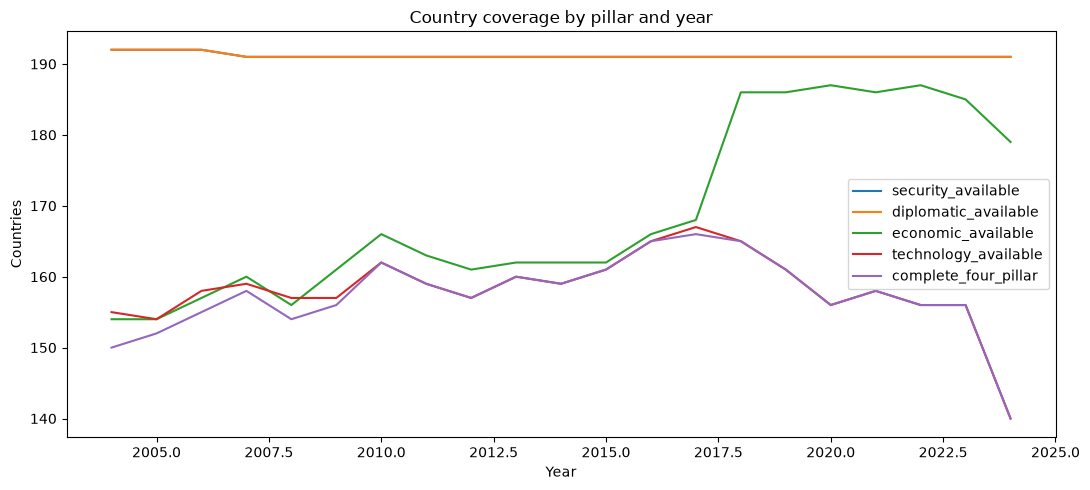

In [10]:
ax = coverage_by_year.plot(
    x="year",
    y=[
        "security_available", "diplomatic_available",
        "economic_available", "technology_available",
        "complete_four_pillar",
    ],
    figsize=(11, 5),
)
ax.set(title="Country coverage by pillar and year", xlabel="Year", ylabel="Countries")
plt.tight_layout()
plt.show()

## 10. Sign and coherence diagnostics

A correlation matrix is not a test of validity, but it is a useful audit for accidentally reversed signs and unexpectedly disconnected pillars. Negative correlations may be substantively real and should be investigated rather than automatically corrected.

In [11]:
correlation = index_panel[PILLAR_COLUMNS + [
    "closeness_index_equal_weight",
    "closeness_index_available_weight",
]].corr()
correlation.round(3)

,security_score,diplomatic_score,economic_score,technology_score,closeness_index_equal_weight,closeness_index_available_weight
security_score,1.000,0.391,0.351,0.053,0.597,0.594
diplomatic_score,0.391,1.000,0.274,0.054,0.493,0.515
economic_score,0.351,0.274,1.000,0.615,0.814,0.810
technology_score,0.053,0.054,0.615,1.000,0.773,0.774
closeness_index_equal_weight,0.597,0.493,0.814,0.773,1.000,1.000
closeness_index_available_weight,0.594,0.515,0.810,0.774,1.000,1.000


In [12]:
annual_summary = index_panel.groupby("year").agg(
    median_equal_weight=("closeness_index_equal_weight", "median"),
    median_available_weight=("closeness_index_available_weight", "median"),
    mean_equal_weight=("closeness_index_equal_weight", "mean"),
    mean_available_weight=("closeness_index_available_weight", "mean"),
).reset_index()
annual_summary

,year,median_equal_weight,median_available_weight,mean_equal_weight,mean_available_weight
0,2004,0.083103,0.081218,0.079156,0.068776
1,2005,0.028314,0.028314,0.035627,0.034877
2,2006,-0.013246,-0.018705,-0.007001,-0.008749
3,2007,-0.085733,-0.085335,-0.043047,-0.041973
4,2008,-0.119111,-0.119547,-0.085958,-0.088186
5,2009,-0.124041,-0.109804,-0.097996,-0.091771
6,2010,-0.150260,-0.150260,-0.123550,-0.124374
7,2011,-0.118543,-0.118543,-0.115061,-0.115113
8,2012,-0.149786,-0.149786,-0.109534,-0.110610
9,2013,-0.143350,-0.143350,-0.124764,-0.125046


## 11. Dashboard-ready long table

The wide table is convenient for maps and country profiles. The long table is convenient for component selectors, legends, tooltips, and comparison charts.

The dashboard should recalculate its user-weighted index from the four pillar columns, not from rounded display values.

In [13]:
index_long = index_dashboard.melt(
    id_vars=[
        "country_iso3", "preferred_country_name", "year",
        "closeness_index_equal_weight", "closeness_index_available_weight",
        "available_pillar_count", "missing_pillars", "index_status",
        "us_relationship_condition", "us_relationship_condition_severity",
        "china_relationship_condition", "china_relationship_condition_severity",
    ],
    value_vars=PILLAR_COLUMNS,
    var_name="pillar",
    value_name="pillar_score",
)
index_long["pillar"] = index_long["pillar"].str.replace("_score", "", regex=False)
index_long.head()

,country_iso3,preferred_country_name,year,closeness_index_equal_weight,closeness_index_available_weight,available_pillar_count,missing_pillars,index_status,us_relationship_condition,us_relationship_condition_severity,china_relationship_condition,china_relationship_condition_severity,pillar,pillar_score
0,AFG,Afghanistan,2004,NaN,NaN,2,economic|technology,insufficient_pillars,strained,1,strained,1,security,0.000000
1,AFG,Afghanistan,2005,NaN,NaN,2,economic|technology,insufficient_pillars,strained,1,strained,1,security,0.141791
2,AFG,Afghanistan,2006,NaN,NaN,2,economic|technology,insufficient_pillars,strained,1,strained,1,security,0.135714
3,AFG,Afghanistan,2007,NaN,NaN,2,economic|technology,insufficient_pillars,strained,1,strained,1,security,0.263158
4,AFG,Afghanistan,2008,-0.406509,-0.406509,4,,complete_four_pillar,strained,1,strained,1,security,0.252232


## 12. Optional notebook sliders

These widgets demonstrate the same interaction intended for the dashboard. They are optional and do not form part of the production data pipeline. If `ipywidgets` is installed, moving a slider recalculates the selected country's series.

The durable dashboard contract is the `calculate_weighted_index` function and the four pillar score columns, not the notebook widget implementation.

In [14]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    country_options = (
        index_panel[["preferred_country_name", "country_iso3"]]
        .dropna().drop_duplicates().sort_values("preferred_country_name")
    )
    country_dropdown = widgets.Dropdown(
        options=[(row.preferred_country_name, row.country_iso3) for row in country_options.itertuples()],
        description="Country",
    )
    sliders = {
        pillar: widgets.FloatSlider(value=25, min=0, max=100, step=1, description=pillar.title())
        for pillar in ["security", "diplomatic", "economic", "technology"]
    }
    output = widgets.Output()

    def refresh(*_):
        weights = {f"{pillar}_score": slider.value for pillar, slider in sliders.items()}
        result = calculate_weighted_index(index_panel, weights)
        selected = index_panel.loc[index_panel["country_iso3"].eq(country_dropdown.value), ["year"]].copy()
        selected["slider_weighted_index"] = result.loc[selected.index, "weighted_index"]
        with output:
            clear_output(wait=True)
            ax = selected.plot(x="year", y="slider_weighted_index", ylim=(-1, 1), figsize=(9, 4), legend=False)
            ax.axhline(0, color="black", linewidth=0.8)
            ax.set(title=f"User-weighted index: {country_dropdown.label}", ylabel="Index score")
            plt.show()

    country_dropdown.observe(refresh, names="value")
    for slider in sliders.values():
        slider.observe(refresh, names="value")
    display(country_dropdown, *sliders.values(), output)
    refresh()
except ImportError:
    print("ipywidgets is not installed. The dashboard-ready weighting function is still available.")

Dropdown(description='Country', options=(('Afghanistan', 'AFG'), ('Albania', 'ALB'), ('Algeria', 'DZA'), ('And…

FloatSlider(value=25.0, description='Security', step=1.0)

FloatSlider(value=25.0, description='Diplomatic', step=1.0)

FloatSlider(value=25.0, description='Economic', step=1.0)

FloatSlider(value=25.0, description='Technology', step=1.0)

Output()

## 13. Export production tables

Exports are disabled by default to avoid creating artefacts in an uncertain repository location. Once the canonical output directory is confirmed, set `WRITE_OUTPUTS = True` and set `OUTPUT_DIR` below to that established path.

In [15]:
OUTPUT_DIR = ROOT / "outputs" / "tables" / "closeness_index"

if WRITE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    index_dashboard.to_csv(OUTPUT_DIR / "us_china_closeness_index_country_year.csv", index=False)
    index_long.to_csv(OUTPUT_DIR / "us_china_closeness_index_long.csv", index=False)
    coverage_by_year.to_csv(OUTPUT_DIR / "us_china_closeness_index_coverage_by_year.csv", index=False)
    metadata = {
        "baseline_period": [BASELINE_START, BASELINE_END],
        "sign_convention": "positive_US_negative_China",
        "technology_score_column": TECHNOLOGY_SCORE_COLUMN,
        "default_weights": DEFAULT_WEIGHTS,
        "minimum_available_pillars": MIN_AVAILABLE_PILLARS,
        "relationship_condition_role": "dashboard_context_not_index_input",
    }
    (OUTPUT_DIR / "us_china_closeness_index_metadata.json").write_text(
        json.dumps(metadata, indent=2) + "\n", encoding="utf-8"
    )
    print(f"Wrote outputs to {OUTPUT_DIR.relative_to(ROOT)}")
else:
    print("WRITE_OUTPUTS is False; no repository artefacts were written.")

WRITE_OUTPUTS is False; no repository artefacts were written.


## 14. Final validation summary

This final cell confirms that the assembled keys are unique, score ranges are valid, and the dashboard tables contain the expected fields.

In [16]:
assert_unique(index_dashboard, ["country_iso3", "year"], "dashboard output")
assert index_panel["closeness_index_equal_weight"].dropna().between(-1, 1).all()
assert index_panel["closeness_index_available_weight"].dropna().between(-1, 1).all()
assert set(PILLAR_COLUMNS).issubset(index_dashboard.columns)
assert {
    "us_relationship_condition", "china_relationship_condition",
    "us_relationship_condition_severity", "china_relationship_condition_severity",
}.issubset(index_dashboard.columns)

validation_summary = pd.Series({
    "country_year_rows": len(index_dashboard),
    "countries": index_dashboard["country_iso3"].nunique(),
    "first_year": int(index_dashboard["year"].min()),
    "last_year": int(index_dashboard["year"].max()),
    "complete_four_pillar_scores": int(index_dashboard["closeness_index_equal_weight"].notna().sum()),
    "available_weight_scores": int(index_dashboard["closeness_index_available_weight"].notna().sum()),
    "duplicate_country_year_keys": int(index_dashboard.duplicated(["country_iso3", "year"]).sum()),
})
validation_summary

country_year_rows              4014
countries                       192
first_year                     2004
last_year                      2024
complete_four_pillar_scores    3306
available_weight_scores        3564
duplicate_country_year_keys       0
dtype: int64